# Iris: Exploratory Analysis, PCA and K-Means Clustering

1. Exploratory data analysis of the Iris measurements
2. PCA for dimensionality reduction and visualisation
3. K-Means clustering: intuition on synthetic blobs, then on Iris, with the number of clusters chosen by **elbow and silhouette** together, and results validated by **ARI / NMI and a contingency table**, not by accuracy

Clustering is unsupervised, so there is no train/test split; the species labels are used only to check the result afterwards.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.datasets import load_iris, make_blobs
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)   # matplotlib/seaborn colormap notice, harmless
sns.set_theme(style="whitegrid")

## 1. Exploratory data analysis

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("shape:", df.shape, "| missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print(df.species.value_counts().to_dict())
df.describe().round(2)

shape: (150, 5) | missing values: 0 | duplicate rows: 1
{'setosa': 50, 'versicolor': 50, 'virginica': 50}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


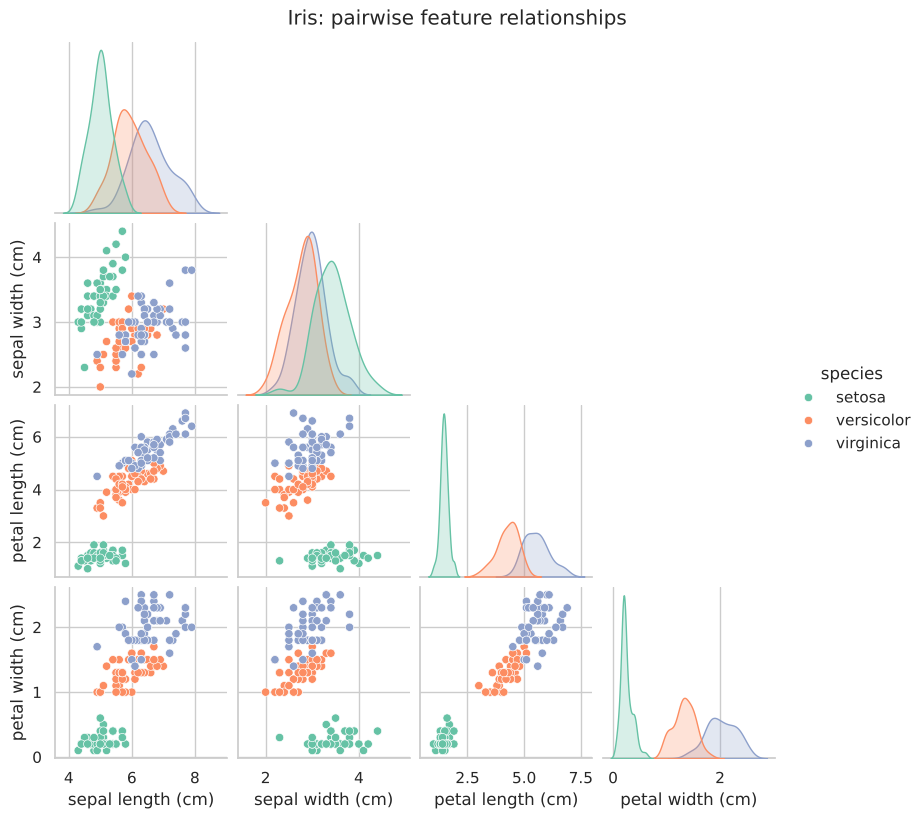

In [3]:
g = sns.pairplot(df, hue='species', palette='Set2', corner=True, height=2)
g.figure.suptitle("Iris: pairwise feature relationships", y=1.02)
plt.show()

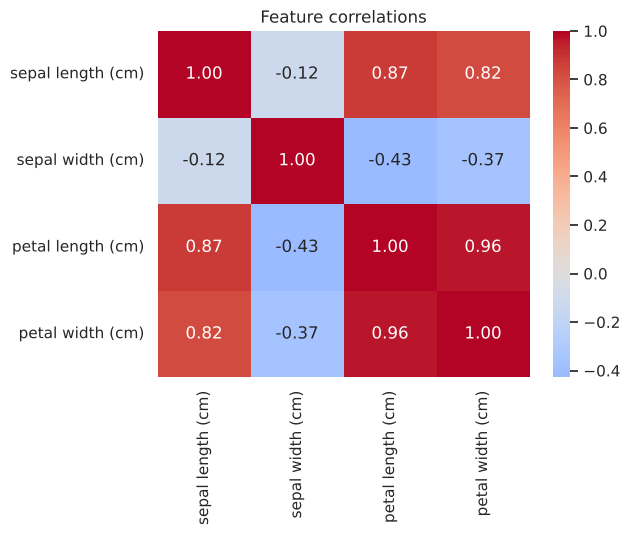

In [4]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df.drop(columns='species').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Feature correlations"); plt.show()

**EDA findings.** 150 rows, no missing values, one exact duplicate row (harmless here and left in, as it is part of the standard dataset), three perfectly balanced species (50 each). The petal measurements are strongly correlated with each other (r ≈ 0.96) and separate the species best; *setosa* is cleanly separated while *versicolor* and *virginica* overlap. One or two principal components should therefore carry almost all of the information.

# K-Means Clustering



## What is Clustering?

Clustering is an **unsupervised learning** technique used to group similar data points into clusters. Unlike classification, clustering doesn't use labeled data.

## Types of Clustering Algorithms
- **Partition-based**: e.g., K-Means
- **Density-based**: e.g., DBSCAN
- **Hierarchical**: e.g., Agglomerative, Divisive

## Applications
- Customer segmentation
- Image compression
- Market basket analysis
- Topic modeling

We'll explore **K-Means Clustering** using simple examples and real-world datasets. We'll start with 2D **synthetic data** for better visualization and understanding.


## Intuition Behind K-Means

K-Means aims to:
1. Divide the dataset into **K clusters**
2. Each cluster has a **centroid** (center)
3. Each point belongs to the cluster whose centroid is **closest (by Euclidean distance)**

The algorithm tries to **minimize the total within-cluster variance** (also called inertia or SSE: Sum of Squared Errors).


## Mathematical Formulation

Let:

- $X = \{x_1, x_2, ..., x_n\}$ be the dataset
- $\mu_k$ be the centroid of cluster $k$
- $C_k$ be the set of points assigned to cluster $k$

**Objective**:
Minimize the **Sum of Squared Distances** of each point to its assigned centroid:

$$
J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \| x_i - \mu_k \|^2
$$


## K-Means Algorithm

1. Choose the number of clusters $K$
2. Initialize $K$ centroids randomly
3. Repeat until convergence:
   - Assign each point to the nearest centroid (cluster assignment)
   - Recalculate centroids as the mean of all points in a cluster

In [5]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

In [6]:
# Generate synthetic 2D data
X, y_true = make_blobs(n_samples=100, centers=4, cluster_std=1.0, random_state=42)

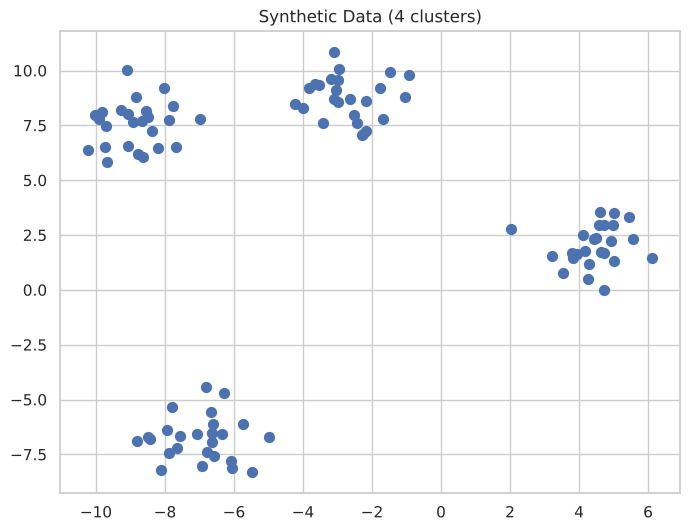

In [7]:
# Plot
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Synthetic Data (4 clusters)")
plt.grid(True)
plt.show()

In [8]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X)
print(f"Adjusted Rand index vs. generating blobs: {adjusted_rand_score(y_true, y_kmeans):.3f}   silhouette: {silhouette_score(X, y_kmeans):.3f}")

Adjusted Rand index vs. generating blobs: 1.000   silhouette: 0.794


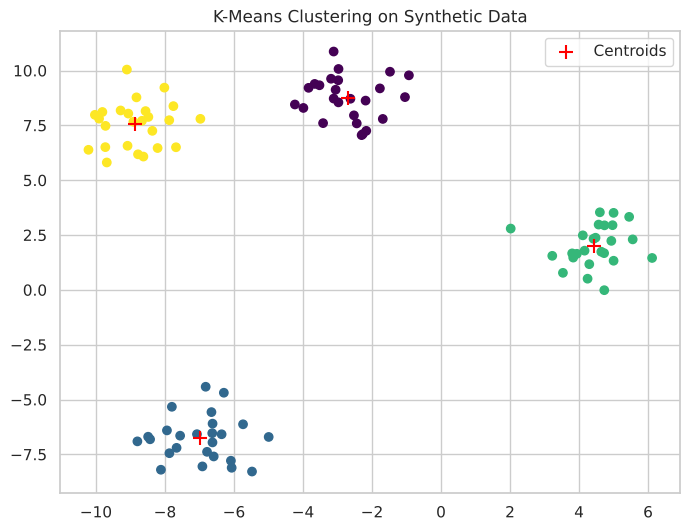

In [9]:
# Plot clusters with centroids
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=100, c='red', marker='+', label='Centroids')
plt.title("K-Means Clustering on Synthetic Data")
plt.legend()
plt.grid(True)
plt.show()


## Objective Function

K-Means minimizes this cost function:

$$
J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \| x_i - \mu_k \|^2
$$

This is called **inertia** in scikit-learn. Lower inertia means tighter clusters.


## Choosing K: elbow and silhouette

Inertia always falls as K grows, so on its own it can only point to a bend ("elbow"), which is often ambiguous. The silhouette score (higher is better, defined for K ≥ 2) is a second opinion. Both are shown for the synthetic data, whose true K is 4.

K with highest silhouette: 4


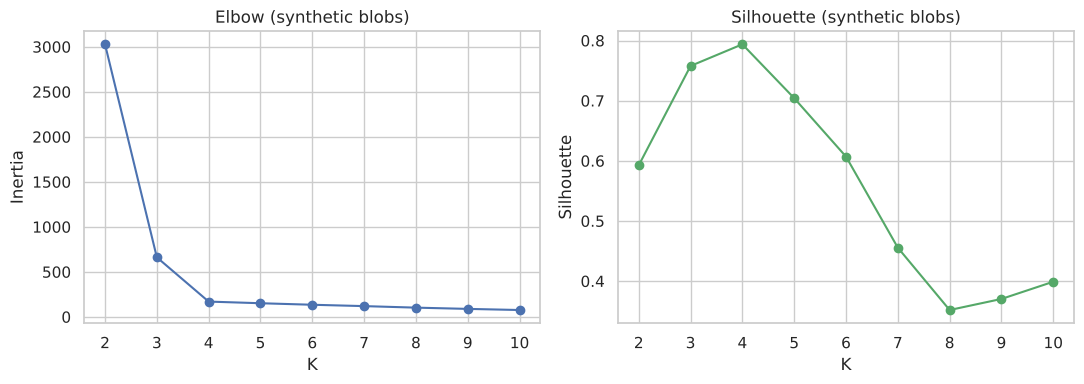

In [10]:
def k_sweep(data_, ks=range(2, 11)):
    out = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data_)
        out.append((k, km.inertia_, silhouette_score(data_, km.labels_)))
    return pd.DataFrame(out, columns=['k', 'inertia', 'silhouette']).set_index('k')

def plot_sweep(sweep, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(sweep.index, sweep.inertia, 'bo-'); axes[0].set_title(f'Elbow ({title})'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia')
    axes[1].plot(sweep.index, sweep.silhouette, 'go-'); axes[1].set_title(f'Silhouette ({title})'); axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette')
    plt.tight_layout(); plt.show()

sweep_blobs = k_sweep(X)
plot_sweep(sweep_blobs, 'synthetic blobs')
print("K with highest silhouette:", sweep_blobs.silhouette.idxmax())

The elbow and the silhouette peak agree at K = 4 for well-separated blobs. Real data is rarely this clean, as the Iris results below show.

## 2. K-Means on Iris

### Does scaling change the answer?

Features are all in centimetres, but the standard recipe for K-Means is to standardise. The two options are compared, along with cluster stability: ARI between runs using 20 different random initialisations.

In [11]:
X_raw = iris.data
X_std = StandardScaler().fit_transform(iris.data)

rows = []
for name, data_ in [('raw (cm)', X_raw), ('standardised', X_std)]:
    km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(data_)
    runs = [KMeans(n_clusters=3, n_init=1, random_state=s).fit_predict(data_) for s in range(20)]
    stability = np.mean([adjusted_rand_score(runs[0], r) for r in runs[1:]])
    rows.append((name, silhouette_score(data_, km.labels_), adjusted_rand_score(iris.target, km.labels_),
                 normalized_mutual_info_score(iris.target, km.labels_), stability))
pd.DataFrame(rows, columns=['features', 'silhouette', 'ARI_vs_species', 'NMI_vs_species', 'stability_ARI_over_seeds']).set_index('features').round(3)

,silhouette,ARI_vs_species,NMI_vs_species,stability_ARI_over_seeds
features,,,,
raw (cm),0.553,0.73,0.758,0.992
standardised,0.460,0.62,0.659,0.798


In [12]:
# Final model: K=3 (see the discussion of K below)
kmeans_iris = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_raw)
df['Cluster'] = kmeans_iris.labels_
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,Cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1


### Choosing K on Iris

K with highest silhouette: 2


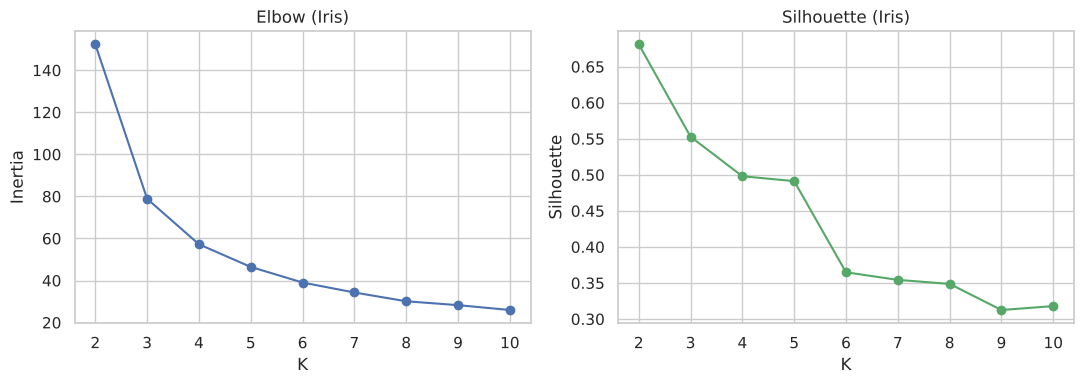

,inertia,silhouette
k,,
2,152.348,0.681
3,78.851,0.553
4,57.228,0.498
5,46.461,0.491
6,39.040,0.365
7,34.306,0.354
8,30.132,0.349
9,28.291,0.313
10,25.971,0.318


In [13]:
sweep_iris = k_sweep(X_raw)
plot_sweep(sweep_iris, 'Iris')
print("K with highest silhouette:", sweep_iris.silhouette.idxmax())
sweep_iris.round(3)

**K = 2 or 3?** The elbow is soft (a bend between 2 and 3) and the silhouette is highest at K = 2: *setosa* is far from everything else, while *versicolor* and *virginica* touch. K = 3 is chosen here because it matches the three species and is what a domain expert would ask for, but it is a judgement call, and the internal metrics alone would not have found it.

Explained variance ratio: [0.925 0.053] | total: 0.978


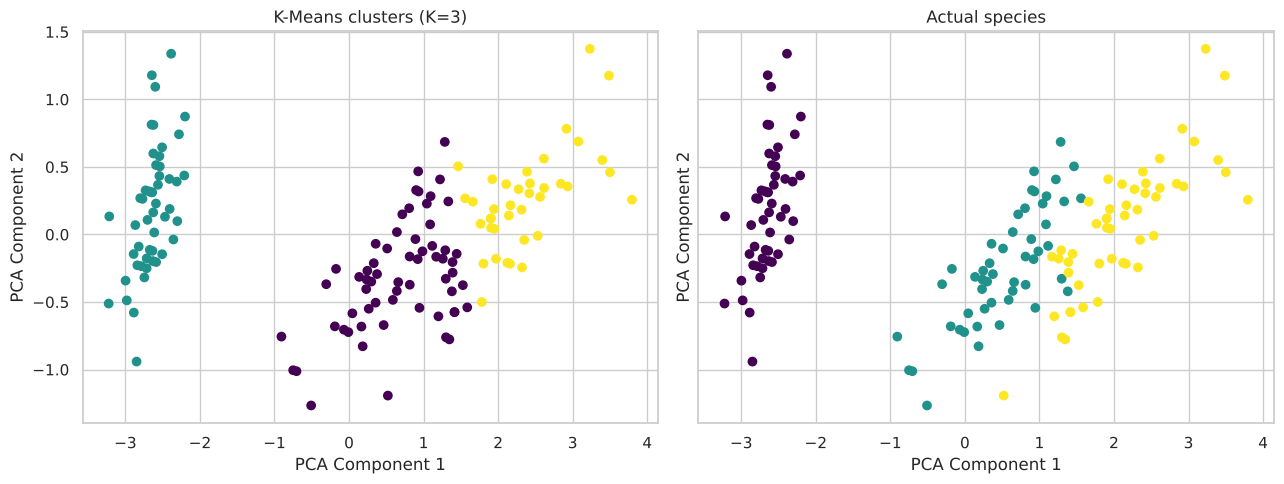

In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_raw)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3), "| total:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=df['Cluster'], cmap='viridis'); axes[0].set_title("K-Means clusters (K=3)")
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target, cmap='viridis'); axes[1].set_title("Actual species")
for ax in axes: ax.set_xlabel("PCA Component 1"); ax.set_ylabel("PCA Component 2")
plt.tight_layout(); plt.show()

In [15]:
print(pd.crosstab(pd.Series(iris.target_names[iris.target], name='species'), df['Cluster'].rename('cluster')))
print(f"\nAdjusted Rand index: {adjusted_rand_score(iris.target, df['Cluster']):.3f}   "
      f"NMI: {normalized_mutual_info_score(iris.target, df['Cluster']):.3f}   "
      f"silhouette: {silhouette_score(X_raw, df['Cluster']):.3f}")

cluster      0   1   2
species               
setosa       0  50   0
versicolor  48   0   2
virginica   14   0  36

Adjusted Rand index: 0.730   NMI: 0.758   silhouette: 0.553


## Summary and methodology notes

- K-Means minimises within-cluster variance (inertia); it assumes roughly spherical clusters of similar size.
- K is chosen with elbow **and** silhouette, then sanity-checked against domain knowledge; they can disagree, as on Iris.
- Use `n_init` explicitly (here 10) so results do not depend on a single random start, and check stability across seeds.
- Compare with the labels via ARI / NMI and a contingency table, not accuracy or a confusion matrix, because cluster ids are arbitrary.
- PCA is used here for visualisation; the clustering itself runs on all four original dimensions.
- Iris is small and clean, so these scores do not predict performance on messier data.